![Imgur](https://i.imgur.com/A0T6cjl.png)
### [<font size = 2 color="#5890FF">SERIES 3</font>](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents)<font size = 2 color="#7B8698">　‣　D A T A　E X P L O R A T I O N　🔭<br></font>[Introduction](https://www.kaggle.com/code/samybaladram/03-1-data-exploration-introduction)・**Summary Statistics**・[Distribution Types](https://www.kaggle.com/samybaladram/03-3-data-exploration-distribution-types)・[Distribution Fitting](https://www.kaggle.com/code/samybaladram/03-4-data-exploration-distribution-fitting)・[Bivariate Analysis](https://www.kaggle.com/code/samybaladram/03-5-data-exploration-bivariate-analysis)<p>
---

# What is **Measures of Central Tendencies**?
![Imgur](https://i.imgur.com/pTpV7TO.png)
![Imgur](https://i.imgur.com/o75ielq.png)

# 📊　Dataset & Libraries Used
![Imgur](https://i.imgur.com/s1A2Hac.png)

In [ ]:
# All codes depend on this cell
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 300
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["figure.figsize"] = (4.5, 3.5)

golf_dataset = pd.read_csv("./Data/golf_dataset_weather_tropical_1year.csv")
df = golf_dataset[['Date','Outlook'] + golf_dataset.select_dtypes(include=['number']).columns.tolist()].copy()

df

,Date,Outlook,SunshineDuration,Temperature,Humidity,WindDirection,WindSpeed,Pressure,TotalPlayer,TimePerRound
0,2021-01-01,rainy,1.7,27.2,79,62.0,1.3,1010.3,28,206
1,2021-01-02,sunny,11.8,33.4,70,350.0,0.1,1013.2,74,453
2,2021-01-03,sunny,13.1,31.3,75,345.3,2.2,1005.5,63,290
3,2021-01-04,overcast,0.8,26.8,68,304.2,2.3,1009.6,56,298
4,2021-01-05,sunny,5.1,30.8,59,0.1,6.2,1011.3,70,213
...,...,...,...,...,...,...,...,...,...,...
360,2021-12-27,rainy,2.8,25.0,85,318.9,0.4,1008.1,30,346
361,2021-12-28,rainy,0.3,22.3,71,327.8,0.7,1013.7,26,265
362,2021-12-29,sunny,5.7,29.7,65,343.6,1.9,1010.6,80,442
363,2021-12-30,overcast,4.8,26.8,84,0.6,0.6,1007.5,60,342


# Measures of Central Tendency

![Imgur](https://i.imgur.com/Tb8Hsl7.png)

# 　Mean

![Imgur](https://i.imgur.com/eYZy8ci.png)
![Imgur](https://i.imgur.com/WDdNDss.png)

In [ ]:
df[['Temperature', 'Humidity', 'WindDirection','WindSpeed']].mean()

Temperature       27.080274
Humidity          73.227397
WindDirection    184.251781
WindSpeed          2.812877
dtype: float64

# 　Median

![Imgur](https://i.imgur.com/pKTO1s6.png)
![Imgur](https://i.imgur.com/lZ0UxKy.png)

In [3]:
df[['SunshineDuration', 'WindSpeed', 'TotalPlayer', 'TimePerRound']].median()

SunshineDuration      3.4
WindSpeed             1.9
TotalPlayer          61.0
TimePerRound        309.0
dtype: float64

# 　Mode

![Imgur](https://i.imgur.com/jWW24HD.png)
![Imgur](https://i.imgur.com/PAfQ0tJ.png)

In [4]:
df[['Outlook', 'TotalPlayer', 'Temperature', 'TimePerRound']].mode()

,Outlook,TotalPlayer,Temperature,TimePerRound
0,sunny,60,25.4,290


# Measure of Dispersion & Frequency

![Imgur](https://i.imgur.com/5XdmKjI.png)
![Imgur](https://i.imgur.com/4QTl8BD.png)

# 　Range
![Imgur](https://i.imgur.com/WGFZiQS.png)


In [5]:
temperature_range = df['Temperature'].max() - df['Temperature'].min()

print(temperature_range)

16.0


# 　Standard Deviation
![Imgur](https://i.imgur.com/J0q6lGA.png)
![Imgur](https://i.imgur.com/RoYxeDS.png)
![Imgur](https://i.imgur.com/uCPQPAJ.png)
![Imgur](https://i.imgur.com/xk57ciq.png)

In [6]:
df[['Temperature', 'Humidity', 'WindDirection','WindSpeed']].std()

Temperature        3.073932
Humidity           9.110754
WindDirection    114.360874
WindSpeed          2.963037
dtype: float64

# 　Quartile
![Imgur](https://i.imgur.com/HIbceXg.png)
![Imgur](https://i.imgur.com/IBsAEMQ.png)

In [7]:
Q1 = df[['Temperature', 'Humidity','WindSpeed']].quantile(0.25)
Q2 = df[['Temperature', 'Humidity', 'WindSpeed']].quantile(0.5)
Q3 = df[['Temperature', 'Humidity', 'WindSpeed']].quantile(0.75)

pd.DataFrame({'Q1': Q1, 'Q2': Q2, 'Q3': Q3}).T


,Temperature,Humidity,WindSpeed
Q1,24.9,66.0,0.8
Q2,26.6,72.0,1.9
Q3,29.4,79.0,3.7


# 　Boxplot
![Imgur](https://i.imgur.com/FvriasM.png)

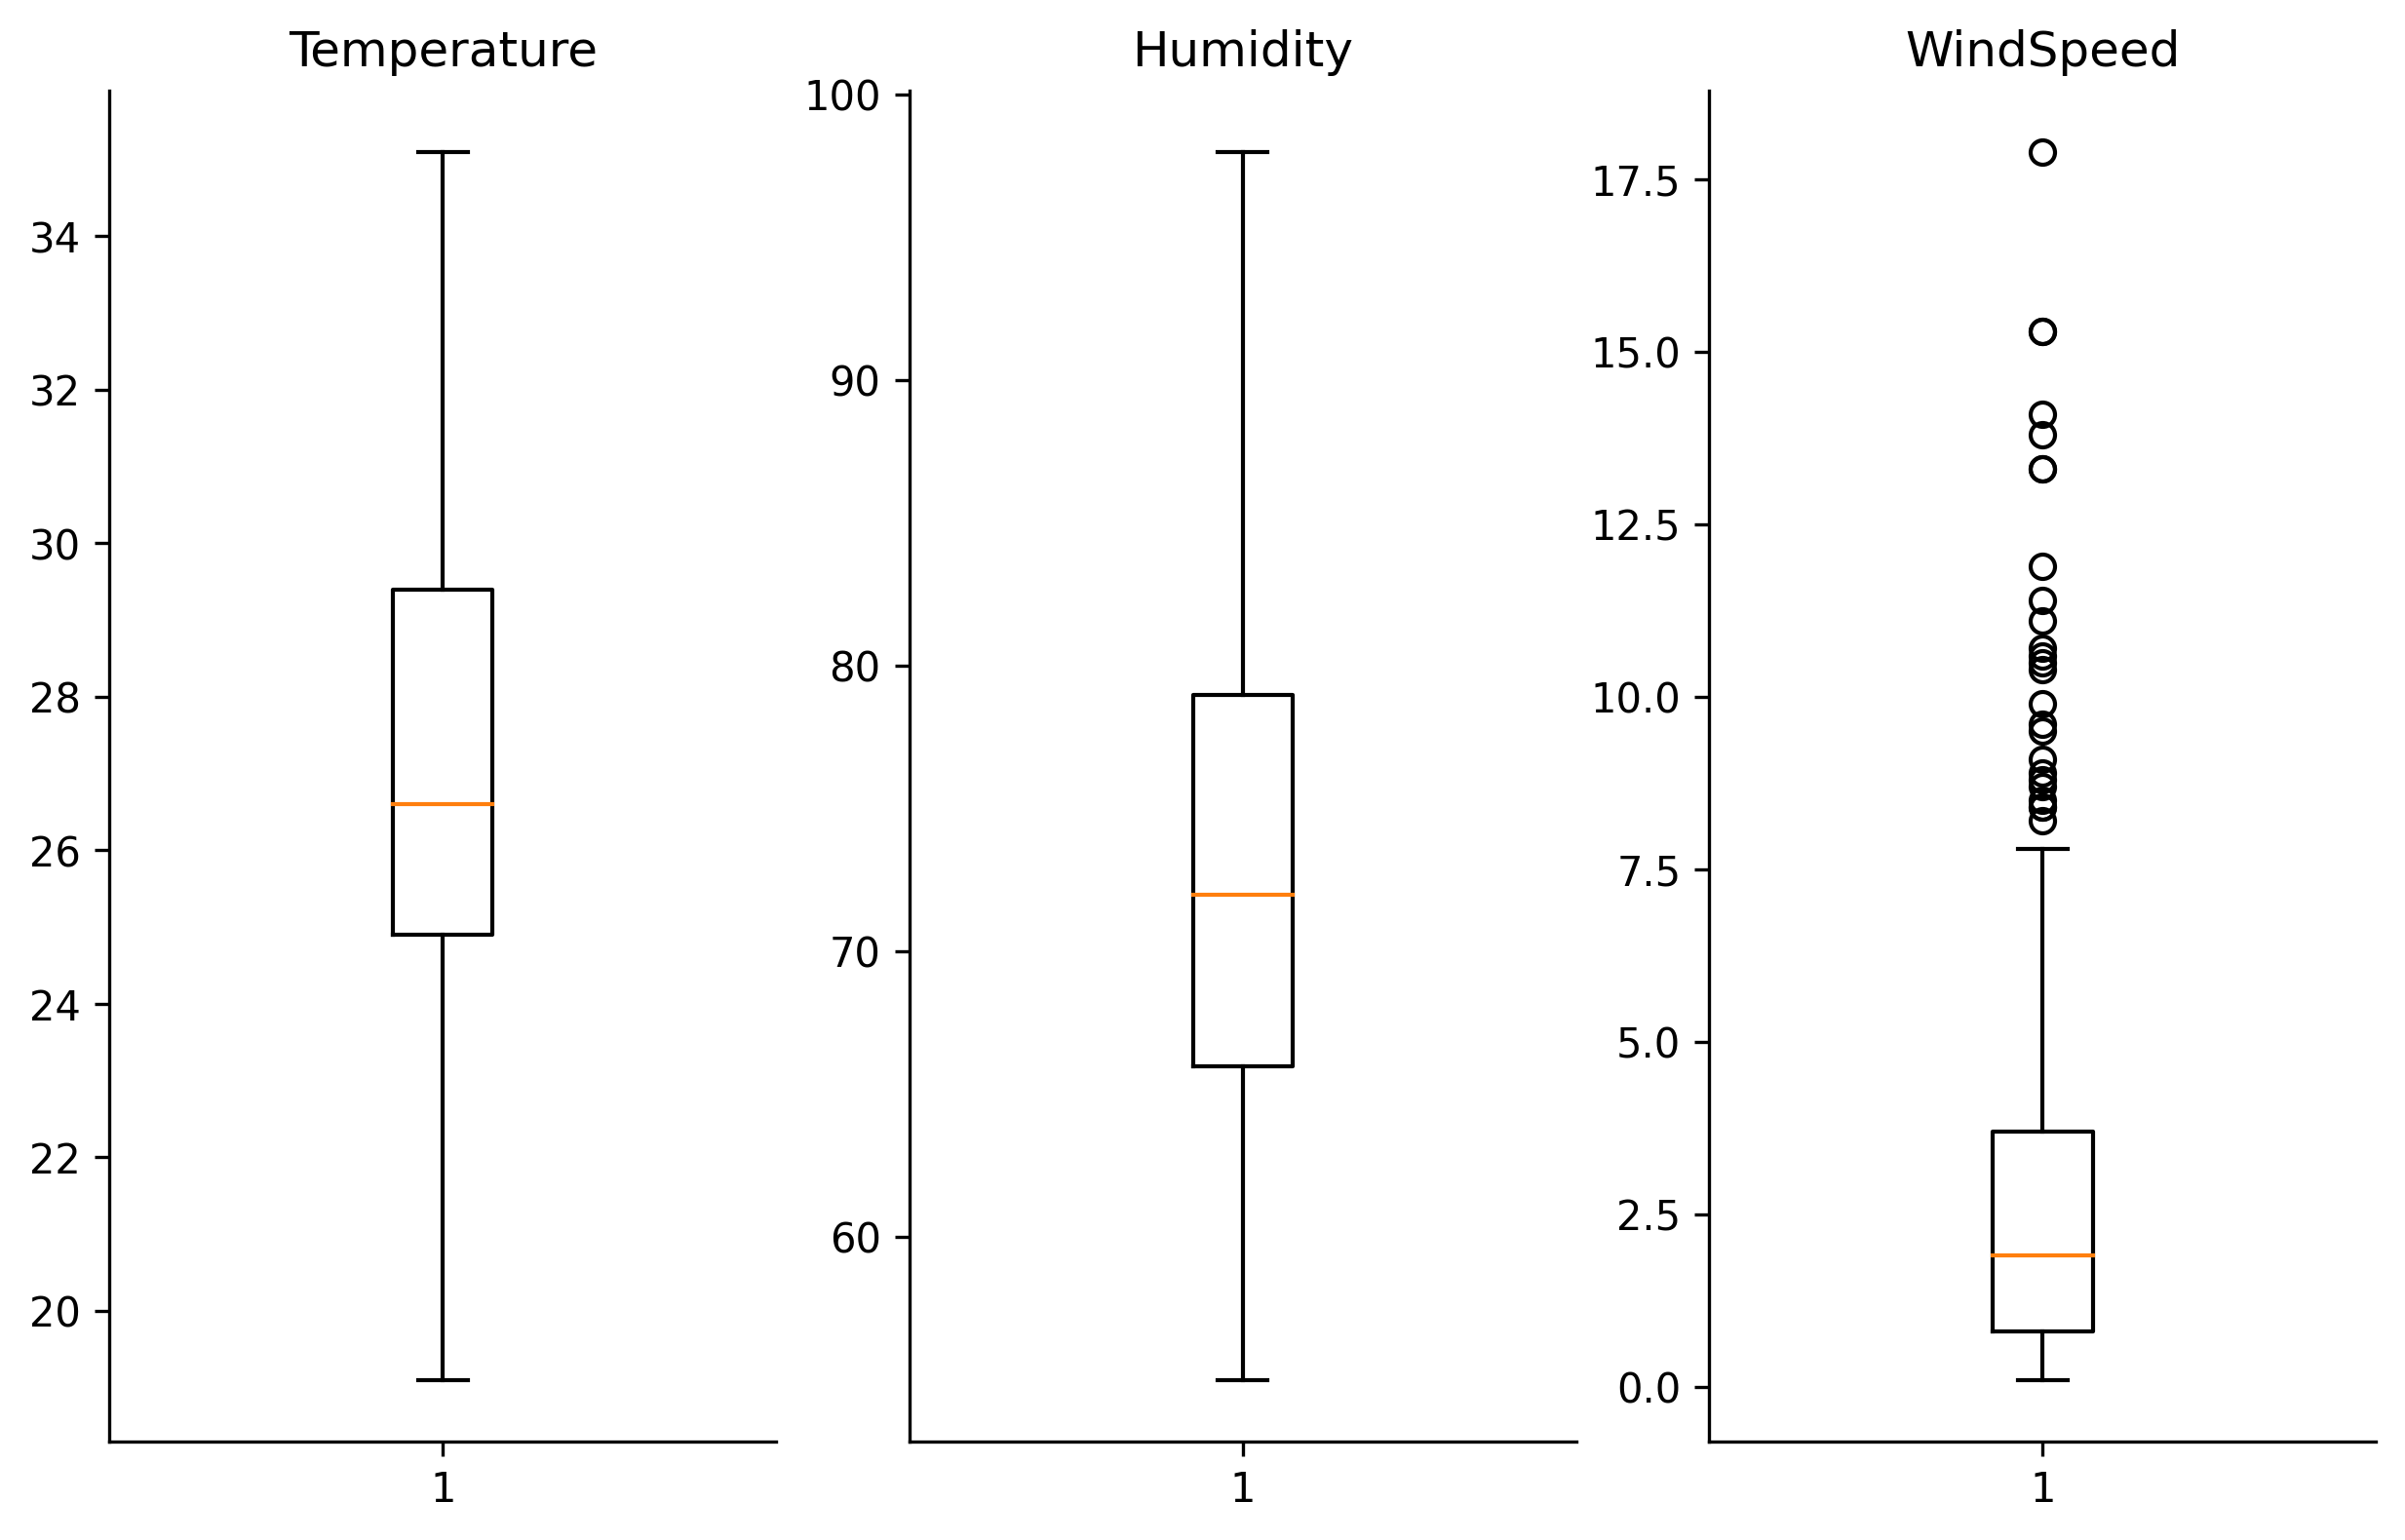

In [8]:
# Q3 and Q1 on the slide above is incorrect. They're supposed to be the other way around.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(10, 6))

for i, col in enumerate(['Temperature', 'Humidity', 'WindSpeed']):
    axes[i].boxplot(df[col])
    axes[i].set_title(col)

plt.show()

# 　Frequency Table
![Imgur](https://i.imgur.com/Gc4Gtcd.png)
![Imgur](https://i.imgur.com/6kJyJZQ.png)

In [9]:
frequency_table = df['Outlook'].value_counts().reset_index()
frequency_table.columns = ['Grade', 'Frequency']

frequency_table

,Grade,Frequency
0,sunny,147
1,overcast,129
2,rainy,89


![Imgur](https://i.imgur.com/CgfY7UK.png)

![Imgur](https://i.imgur.com/M0mwv0l.png)

--- 

*Explore [diverse notebooks full of captivating visuals](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents), each tackling unique facets of the field—all based on some mini, yet enriching, golf play datasets. Your hole-in-one guide to mastering Data Science basics.*


### For a complete list of topics and series, see [⛳️ 📋 Data Science with Golf Dataset・Table of Contents](https://www.kaggle.com/samybaladram/golf-data-analysis-table-of-contents).
---

**Your Feedback Matters! 🍃** If you find this notebook series useful, an ⬆️ *upvote* would be appreciated to help others in the community discover it too!